# 01 · Data and quality control

The two 10x Genomics FFPE sections, the spot filters, and the first differences between the slides:
sequencing depth and tissue composition.

Scope: one normal and one cancer section from two donors. Differences between the slides mix biology with donor, processing and depth effects; see the [README](../README.md#scope).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from prostate_markers import io, viz

config = io.load_config()
fig_dir = io.path(config, "figures")
viz.set_style()
pd.set_option("display.precision", 3)

In [2]:
spots = io.read_table(config, "qc_spots.csv.gz", key="processed")
io.read_table(config, "qc_summary.csv")

,slide,spots_in_tissue,spots_kept,median_counts,median_genes
0,normal,2543,2542,4446.5,2694
1,cancer,4371,4369,10710.0,4979


Space Ranger's filtered matrix already contains only spots under tissue, and the filters in
`config.yaml` (500 to 50,000 counts, at least 250 genes) remove only three of them. The FFPE probe
set has no mitochondrial genes, so mitochondrial fraction cannot be used as a QC metric here.

The larger difference is depth: the cancer section has about 2.4 times the median counts per spot.
Every comparison below uses library-size normalized expression (counts per 10k, log1p), and
fold changes use pseudo-bulk totals, so depth does not enter them directly.

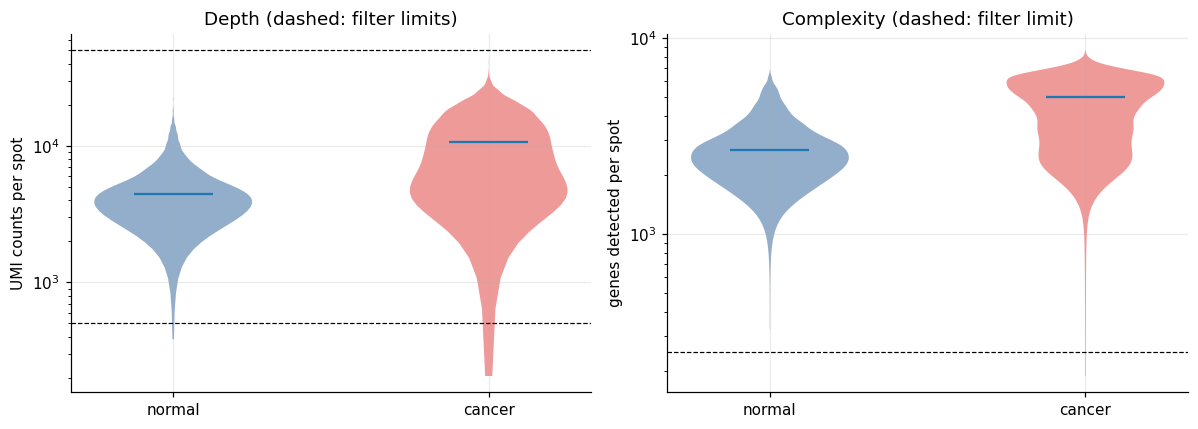

In [3]:
qc = config["qc"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, label, lims in [
    (axes[0], "total_counts", "UMI counts per spot", (qc["min_counts"], qc["max_counts"])),
    (axes[1], "n_genes", "genes detected per spot", (qc["min_genes"], None)),
]:
    data = [spots.loc[spots["slide"] == s, col] for s in io.SLIDES]
    parts = ax.violinplot(data, showmedians=True, showextrema=False)
    for body, s in zip(parts["bodies"], io.SLIDES):
        body.set_facecolor(viz.SLIDE_COLORS[s])
        body.set_alpha(0.6)
    for lim in lims:
        if lim is not None:
            ax.axhline(lim, color="black", lw=0.8, ls="--")
    ax.set_yscale("log")
    ax.set_xticks([1, 2], io.SLIDES)
    ax.set_ylabel(label)
axes[0].set_title("Depth (dashed: filter limits)")
axes[1].set_title("Complexity (dashed: filter limit)")
fig.tight_layout()
viz.save(fig, fig_dir, "01_qc_distributions.png")

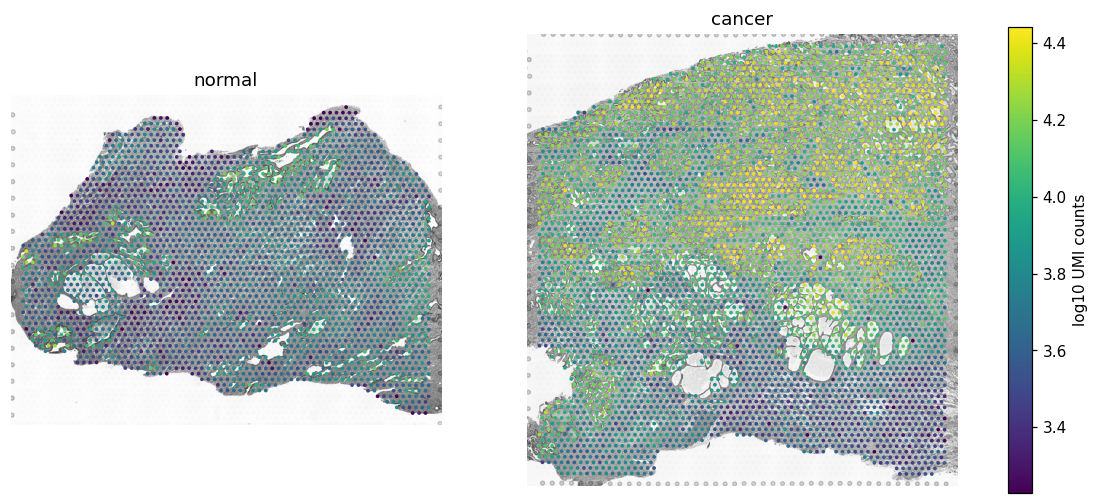

In [4]:
slides = io.read_slides(config)
depth = {s: np.log10(slides[s].obs["total_counts"].to_numpy()) for s in io.SLIDES}
fig = viz.paired_overlay(slides, depth, "log10 UMI counts")
viz.save(fig, fig_dir, "01_depth_spatial.png")

## Tissue composition

Depth is not the only slide-level difference. The two sections contain different proportions of
glandular epithelium and fibromuscular stroma. We summarize each spot with two short gene scores
(mean log-expression): luminal epithelium (`EPCAM`, `KRT8`, `KRT18`) and smooth-muscle stroma
(`ACTA2`, `DES`, `CNN1`).

In [5]:
programs = {
    "epithelial": config["composition"]["epithelial_genes"],
    "stromal": config["composition"]["stromal_genes"],
}

def program_score(adata, genes):
    return np.asarray(adata[:, genes].X.mean(axis=1)).ravel()

composition = pd.DataFrame([
    {"slide": s, "program": p, "mean_score": program_score(slides[s], g).mean()}
    for s in io.SLIDES for p, g in programs.items()
]).pivot(index="program", columns="slide", values="mean_score")[list(io.SLIDES)]
composition

slide,normal,cancer
program,,
epithelial,0.634,1.615
stromal,3.461,2.383


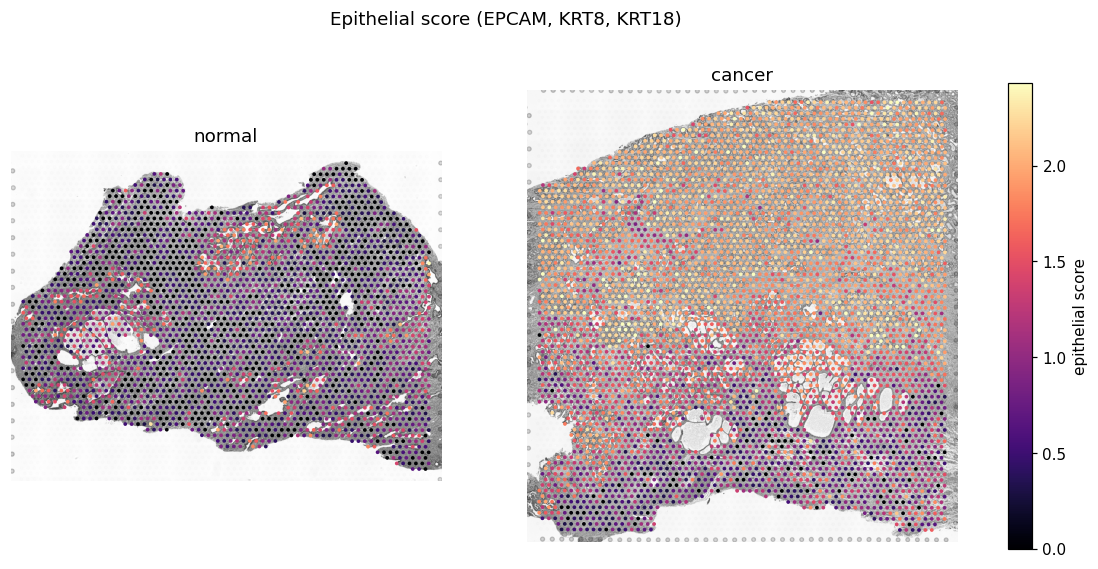

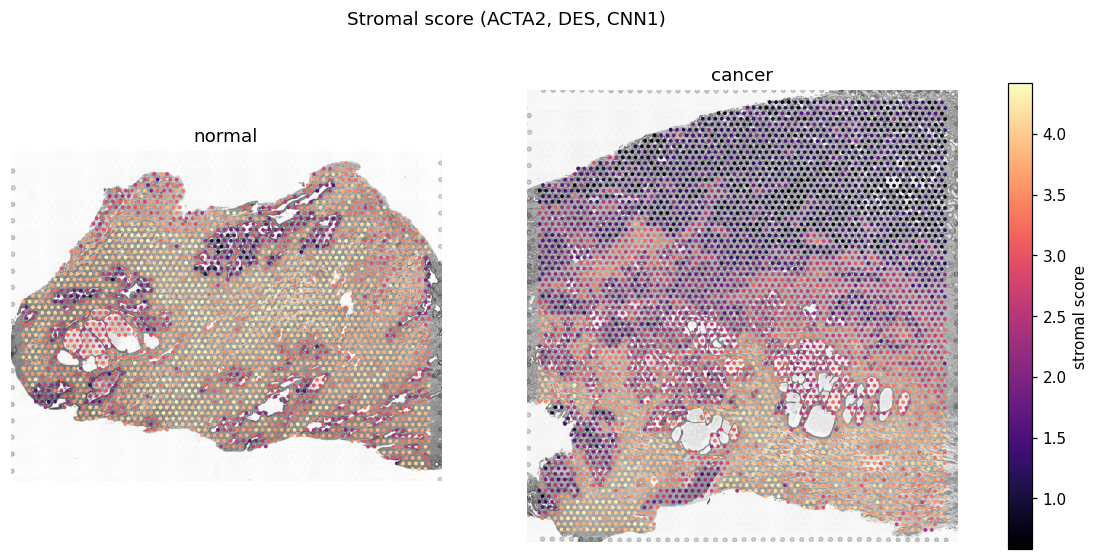

In [6]:
for name, genes in programs.items():
    values = {s: program_score(slides[s], genes) for s in io.SLIDES}
    fig = viz.paired_overlay(slides, values, f"{name} score", cmap="magma")
    fig.suptitle(f"{name.capitalize()} score ({', '.join(genes)})", y=1.0)
    viz.save(fig, fig_dir, f"01_{name}_spatial.png")

The cancer section is richer in luminal epithelium and poorer in smooth-muscle stroma. That alone
moves every epithelial or stromal gene between the slides, whatever its role in cancer. Notebook 02
therefore repeats each fold change within the epithelium-rich third of spots in each slide, and
notebook 03 uses within-slide correlations that composition differences between slides cannot drive.